# 1. Chargement et prétraitement du dataset
- Importer les bibliothèques nécessaires : TensorFlow/Keras, NumPy, Matplotlib, scikit-learn et les autres bibliothèques utiles.
- Charger le dataset de radiographies thoraciques fourni pour le projet.
- Explorer la structure des dossiers et identifier les classes présentes.
- Vérifier le nombre d'images disponibles dans chaque classe.
- Vérifier la répartition des images entre les classes NORMAL et PNEUMONIA.
- Identifier les éventuels problèmes liés aux images et gérer les erreurs de chargement.
- Redimensionner les images à une taille fixe de 180 × 180 pixels et les convertir au format RGB.
- Préparer les images au format attendu par le modèle CNN, avec trois canaux de couleur.
- Associer les labels aux images en utilisant les noms des dossiers.
- Diviser les données en ensembles d'entraînement, de validation et de test. L'ensemble de test doit rester indépendant de l'entraînement.
- Normaliser les valeurs des pixels dans la plage [0, 1], en veillant à appliquer cette transformation une seule fois dans le pipeline de traitement.
- Visualiser un échantillon d'images de chaque classe.
- Afficher graphiquement la distribution des classes.
- Étudier le déséquilibre éventuel entre les classes et envisager une stratégie adaptée pour en limiter les effets.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import kagglehub
from sklearn.utils.class_weight import compute_class_weight

path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
data_dir = os.path.join(path, "chest_xray")

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.


In [2]:
train_dir = os.path.join(data_dir, "train")
val_dir = os.path.join(data_dir, "val")
test_dir = os.path.join(data_dir, "test")

SIZE_IMG = (180, 180)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=SIZE_IMG,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="binary"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    val_dir,
    image_size=SIZE_IMG,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="binary"
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=SIZE_IMG,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="binary"
)

Found 5216 files belonging to 2 classes.
Found 16 files belonging to 2 classes.
Found 624 files belonging to 2 classes.


In [3]:
normalization_layer = tf.keras.layers.Rescaling(1./255)

train_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))
val_ds = val_ds.map(lambda x, y: (normalization_layer(x), y))
test_ds = test_ds.map(lambda x, y: (normalization_layer(x), y))

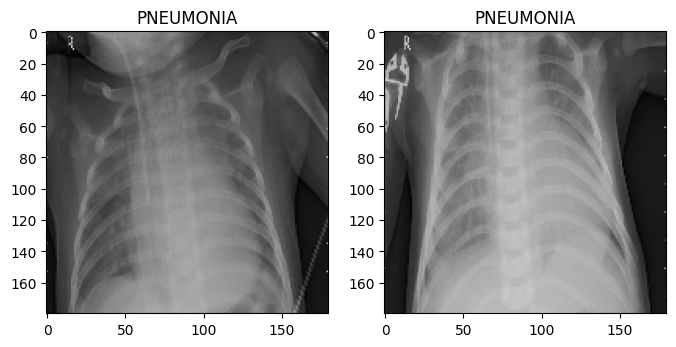

In [22]:
class_names = ["NORMAL", "PNEUMONIA"]
plt.figure(figsize=(8, 4))

for images, labels in train_ds.take(1):
    for i in range(2):
        ax = plt.subplot(1, 2, i + 1)
        plt.imshow(images[i].numpy())
        plt.title(class_names[int(labels[i])])
plt.show()

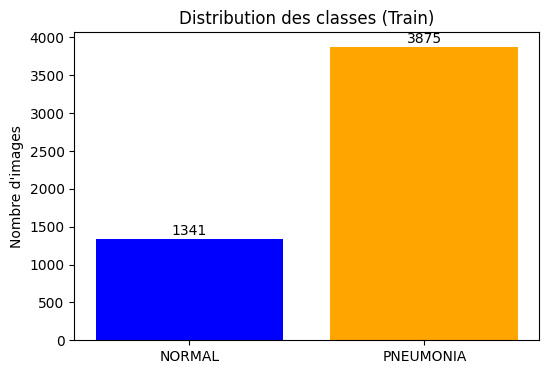

In [24]:
import os
import glob

num_normal = len(glob.glob(os.path.join(train_dir, "NORMAL", "*")))
num_pneumonia = len(glob.glob(os.path.join(train_dir, "PNEUMONIA", "*")))

counts = {"NORMAL": num_normal, "PNEUMONIA": num_pneumonia}
classes = list(counts.keys())
values = list(counts.values())

plt.figure(figsize=(6, 4))
plt.bar(classes, values, color=["blue", "orange"])
plt.title("Distribution des classes (Train)")
plt.ylabel("Nombre d'images")
for i, v in enumerate(values):
    plt.text(i, v + 50, str(v), ha="center")
plt.show()

In [6]:
y_train = []
for _, labels in train_ds:
    y_train.extend(labels.numpy().flatten())
y_train = np.array(y_train)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)
weight_dict = {i: weight for i, weight in enumerate(class_weights)}
print("Poids des classes :", weight_dict)

Poids des classes : {0: np.float64(1.9448173005219984), 1: np.float64(0.6730322580645162)}


In [7]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1)
])

# 2. Conception du modèle CNN
- Comprendre le principe d'un réseau de neurones convolutif et son intérêt pour la classification d'images.
- Définir une architecture CNN comprenant notamment :
  - Des couches Conv2D pour extraire des caractéristiques visuelles.
  - Des couches MaxPooling2D pour réduire progressivement les dimensions des représentations.
  - Une couche Flatten pour préparer les caractéristiques à la classification.
  - Des couches Dense pour réaliser la classification.
  - Une couche Dropout pour contribuer à limiter le surapprentissage.
- Utiliser une fonction d'activation adaptée dans les couches cachées et une fonction de sortie adaptée à une classification binaire.
- Compiler le modèle avec un optimiseur, une fonction de perte et des métriques appropriés.
- Utiliser model.summary() pour examiner l'architecture du modèle et le nombre de paramètres.
- Définir les principaux hyperparamètres : nombre d'époques, taille des lots (batch size) et paramètres d'optimisation.
- Mettre en place, si nécessaire, des techniques d'augmentation des images afin d'améliorer la capacité de généralisation du modèle.

In [8]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(180, 180, 3)),
    data_augmentation,

    tf.keras.layers.Conv2D(16, 3, padding='same', activation='relu'),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(32, 3, padding='same', activation='relu'),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(64, 3, padding='same', activation='relu'),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

In [9]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.Precision(name='precision'), tf.keras.metrics.Recall(name='recall')]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 180, 180, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 90, 90, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 90, 90, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 45, 45, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 45, 45, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 22, 22, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 30976)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,965,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,988,769 (15.22 MB)

 Trainable params: 3,988,769 (15.22 MB)

 Non-trainable params: 0 (0.00 B)

# 3. Entraînement et optimisation du modèle
- Entraîner le CNN à l'aide de model.fit().
- Suivre les performances du modèle sur les ensembles d'entraînement et de validation.
- Visualiser les courbes d'apprentissage : fonction de perte et métriques de performance.
- Identifier les signes éventuels de surapprentissage ou de sous-apprentissage.
- Utiliser des mécanismes de contrôle de l'entraînement, tels que EarlyStopping et ReduceLROnPlateau.
- Étudier les effets du déséquilibre des classes et, si nécessaire, utiliser une stratégie de pondération des classes.
- Mesurer et documenter la durée de l'entraînement.

In [10]:
import time

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=3,
    min_lr=1e-6
)


history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=weight_dict,
    callbacks=[early_stopping, reduce_lr]
)


Epoch 1/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 37s 175ms/step - accuracy: 0.6630 - loss: 0.5554 - precision: 0.8684 - recall: 0.6439 - val_accuracy: 0.8125 - val_loss: 0.5329 - val_precision: 0.7273 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 2/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 30s 186ms/step - accuracy: 0.8715 - loss: 0.3067 - precision: 0.9536 - recall: 0.8694 - val_accuracy: 0.8125 - val_loss: 0.5236 - val_precision: 0.7778 - val_recall: 0.8750 - learning_rate: 0.0010
Epoch 3/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 30s 183ms/step - accuracy: 0.8905 - loss: 0.2615 - precision: 0.9617 - recall: 0.8880 - val_accuracy: 0.6250 - val_loss: 0.8367 - val_precision: 0.5833 - val_recall: 0.8750 - learning_rate: 0.0010
Epoch 4/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 41s 186ms/step - accuracy: 0.9030 - loss: 0.2405 - precision: 0.9680 - recall: 0.8991 - val_accuracy: 0.8125 - val_loss: 0.5135 - val_precision: 0.8571 - val_recall: 0.7500 - learning_rate: 0.0010
Epoch 5/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 34s 209ms/st

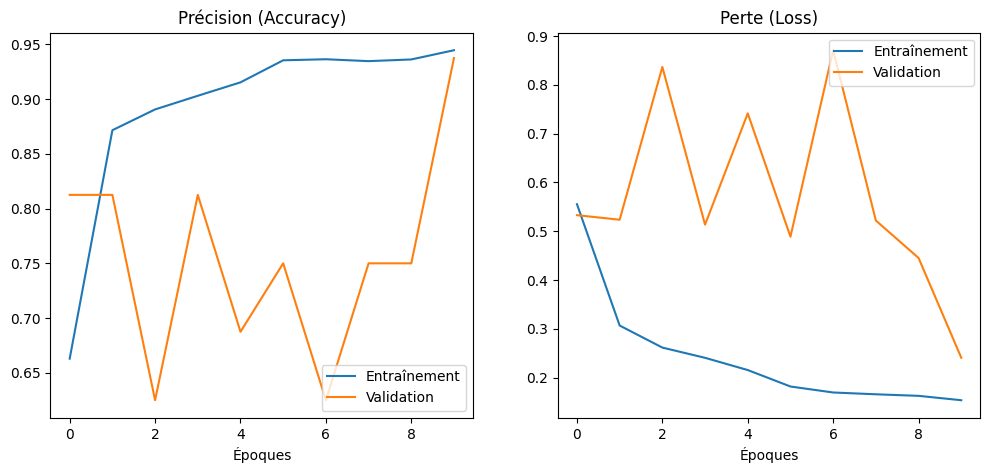

In [11]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(len(acc))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Entraînement')
plt.plot(epochs_range, val_acc, label='Validation')
plt.legend(loc='lower right')
plt.title('Précision (Accuracy)')
plt.xlabel('Époques')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Entraînement')
plt.plot(epochs_range, val_loss, label='Validation')
plt.legend(loc='upper right')
plt.title('Perte (Loss)')
plt.xlabel('Époques')

plt.show()

# 4. Évaluation du modèle
- Évaluer le modèle final sur l'ensemble de test indépendant.
- Calculer et interpréter les métriques de classification :
  - Accuracy.
  - Precision.
  - Recall.
  - F1-score.
  - ROC-AUC.
- Générer une matrice de confusion et un rapport de classification.
- Identifier les faux positifs et les faux négatifs.
- Afficher des exemples de prédictions correctes et incorrectes.
- Analyser les limites du modèle et les erreurs de classification observées.
- Comparer les performances obtenues sur les données d'entraînement, de validation et de test.
- Justifier les choix réalisés et proposer des pistes d'amélioration.

### 4. Évaluation du modèle
Nous allons évaluer le modèle final sur l'ensemble de test indépendant, calculer les métriques clés, et tracer la matrice de confusion.

In [12]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, f1_score
import seaborn as sns

test_loss, test_acc, test_precision, test_recall = model.evaluate(test_ds)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test Precision: {test_precision:.4f}")
print(f"Test Recall: {test_recall:.4f}")

20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 187ms/step - accuracy: 0.8974 - loss: 0.2968 - precision: 0.8956 - recall: 0.9462
Test Loss: 0.2968
Test Accuracy: 0.8974
Test Precision: 0.8956
Test Recall: 0.9462


In [13]:
y_true = []
y_pred_probs = []

for images, labels in test_ds:
    y_true.extend(labels.numpy().flatten())
    preds = model.predict(images, verbose=0)
    y_pred_probs.extend(preds.flatten())

y_true = np.array(y_true)
y_pred_probs = np.array(y_pred_probs)
y_pred = (y_pred_probs > 0.5).astype(int)

test_f1 = f1_score(y_true, y_pred)
test_auc = roc_auc_score(y_true, y_pred_probs)

print(f"Test F1-Score: {test_f1:.4f}")
print(f"Test ROC-AUC: {test_auc:.4f}")

Test F1-Score: 0.9202
Test ROC-AUC: 0.9488


In [14]:
print("\nRapport de classification :")
print(classification_report(y_true, y_pred, target_names=class_names))


Rapport de classification :
              precision    recall  f1-score   support

      NORMAL       0.90      0.82      0.86       234
   PNEUMONIA       0.90      0.95      0.92       390

    accuracy                           0.90       624
   macro avg       0.90      0.88      0.89       624
weighted avg       0.90      0.90      0.90       624



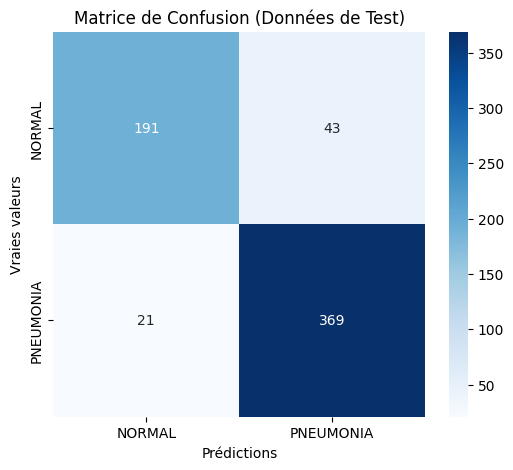

In [15]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Matrice de Confusion (Données de Test)')
plt.xlabel('Prédictions')
plt.ylabel('Vraies valeurs')
plt.show()

### Identification des Erreurs (Faux Positifs & Faux Négatifs)
Identifions les indices des exemples mal classés afin d'inspecter visuellement les images correspondantes.

In [16]:
test_images_all = []
for images, _ in test_ds:
    test_images_all.append(images.numpy())
test_images_all = np.concatenate(test_images_all, axis=0)

idx_tp = np.where((y_true == 1) & (y_pred == 1))[0]
idx_tn = np.where((y_true == 0) & (y_pred == 0))[0]
idx_fp = np.where((y_true == 0) & (y_pred == 1))[0]
idx_fn = np.where((y_true == 1) & (y_pred == 0))[0]

print(f"Vrais Positifs (Pneumonie détectée correctement) : {len(idx_tp)}")
print(f"Vrais Négatifs (Normal détecté correctement) : {len(idx_tn)}")
print(f"Faux Positifs (Sain prédit comme Pneumonie) : {len(idx_fp)}")
print(f"Faux Négatifs (Pneumonie non détectée) : {len(idx_fn)}")

Vrais Positifs (Pneumonie détectée correctement) : 369
Vrais Négatifs (Normal détecté correctement) : 191
Faux Positifs (Sain prédit comme Pneumonie) : 43
Faux Négatifs (Pneumonie non détectée) : 21


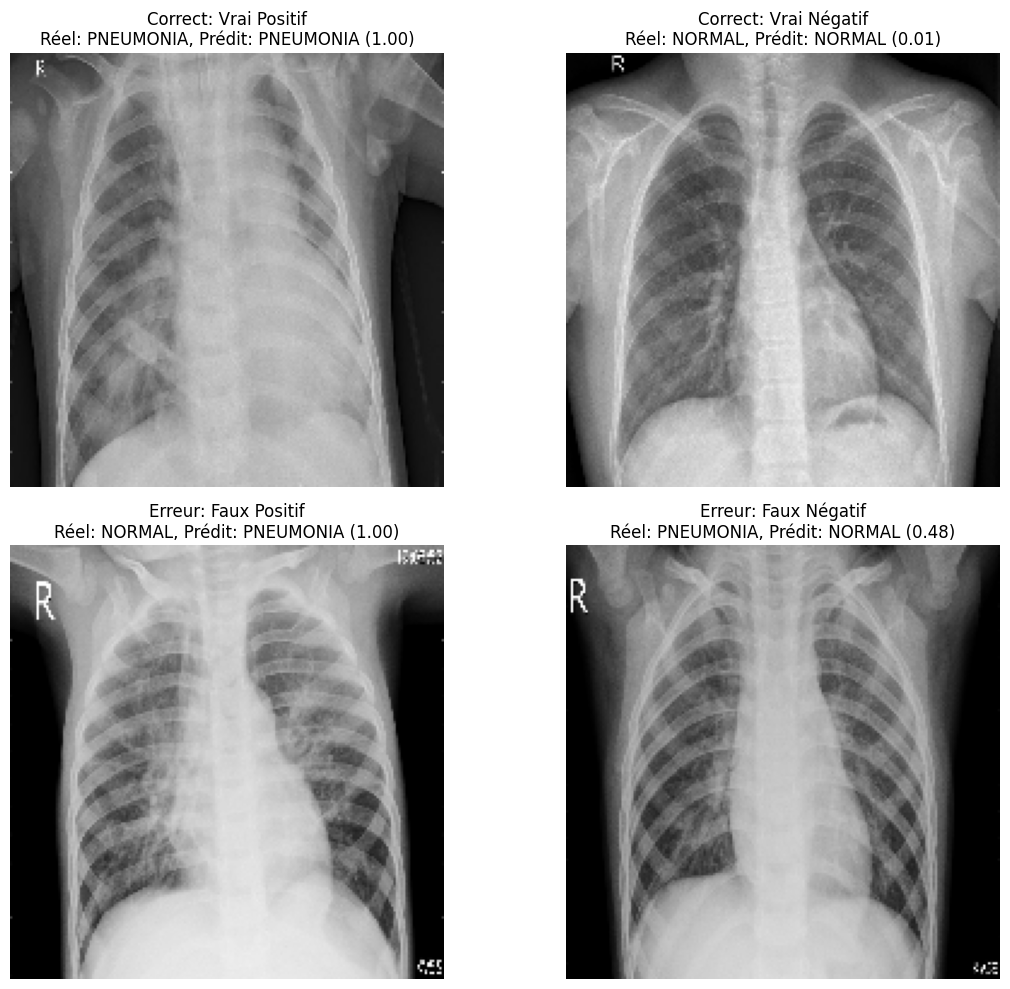

In [17]:
plt.figure(figsize=(12, 10))

plt.subplot(2, 2, 1)
if len(idx_tp) > 0:
    idx = idx_tp[0]
    plt.imshow(test_images_all[idx])
    plt.title(f"Correct: Vrai Positif\nRéel: PNEUMONIA, Prédit: PNEUMONIA ({y_pred_probs[idx]:.2f})")
plt.axis('off')

plt.subplot(2, 2, 2)
if len(idx_tn) > 0:
    idx = idx_tn[0]
    plt.imshow(test_images_all[idx])
    plt.title(f"Correct: Vrai Négatif\nRéel: NORMAL, Prédit: NORMAL ({y_pred_probs[idx]:.2f})")
plt.axis('off')

plt.subplot(2, 2, 3)
if len(idx_fp) > 0:
    idx = idx_fp[0]
    plt.imshow(test_images_all[idx])
    plt.title(f"Erreur: Faux Positif\nRéel: NORMAL, Prédit: PNEUMONIA ({y_pred_probs[idx]:.2f})")
plt.axis('off')

plt.subplot(2, 2, 4)
if len(idx_fn) > 0:
    idx = idx_fn[0]
    plt.imshow(test_images_all[idx])
    plt.title(f"Erreur: Faux Négatif\nRéel: PNEUMONIA, Prédit: NORMAL ({y_pred_probs[idx]:.2f})")
plt.axis('off')

plt.tight_layout()
plt.show()

# 5. Sauvegarde et utilisation du modèle
- Sauvegarder le modèle entraîné au format natif Keras (.keras).
- Sauvegarder les informations nécessaires à son utilisation, notamment la taille des images et les noms des classes, dans un fichier de configuration.
- Recharger le modèle sauvegardé afin de vérifier qu'il peut être réutilisé sans nouvel entraînement.
- Développer une fonction predict_xray(image_path) permettant de :
  - Charger une nouvelle radiographie.
  - Redimensionner et préparer l'image.
  - Effectuer une prédiction avec le modèle.
  - Afficher la classe prédite et le score associé à la classe PNEUMONIA.
- Tester cette fonction sur plusieurs images et analyser les résultats obtenus.

In [ ]:
import json

model_path = "pneumonia_detector.keras"
model.save(model_path)
print(f"Modèle sauvegardé avec succès sous : {model_path}")

config_metadata = {
    "image_size": SIZE_IMG,
    "class_names": class_names
}

config_path = "model_config.json"
with open(config_path, "w") as f:
    json.dump(config_metadata, f, indent=4)
print(f"Configuration sauvegardée sous : {config_path}")

In [ ]:
reloaded_model = tf.keras.models.load_model(model_path)
print("Modèle rechargé avec succès sans nouvel entraînement.")

In [ ]:
def predict_xray(image_path):
    try:
        img = tf.keras.utils.load_img(image_path, target_size=SIZE_IMG, color_mode="rgb")
        img_array = tf.keras.utils.img_to_array(img)

        img_array = img_array / 255.0

        img_array = np.expand_dims(img_array, axis=0)

        prediction_score = reloaded_model.predict(img_array, verbose=0)[0][0]

        predicted_class = "PNEUMONIA" if prediction_score > 0.5 else "NORMAL"

        plt.figure(figsize=(4, 4))
        plt.imshow(img)
        plt.title(f"Classe Prédite: {predicted_class}\nScore PNEUMONIA: {prediction_score:.4f}")
        plt.axis('off')
        plt.show()

        return predicted_class, prediction_score
    except Exception as e:
        print(f"Erreur lors du traitement ou de la prédiction : {e}")
        return None, None

In [ ]:
import glob

test_normal_images = glob.glob(os.path.join(test_dir, "NORMAL", "*"))
test_pneumonia_images = glob.glob(os.path.join(test_dir, "PNEUMONIA", "*"))

print("--- Test sur une image Saine (NORMAL) ---")
if test_normal_images:
    predict_xray(test_normal_images[0])

print("--- Test sur une image de Pneumonie (PNEUMONIA) ---")
if test_pneumonia_images:
    predict_xray(test_pneumonia_images[0])